# Is the DFW labor market cooling?

A short, honest read of the Dallas–Fort Worth–Arlington labor market using the same data as the
[DFW Economy Dashboard](https://ratemyguy.github.io/dfw-economy-dashboard/): BLS payroll jobs (CES),
unemployment (LAUS, CPS), hourly earnings and CPI-U, pulled from the BLS Public Data API by `src/fetch.py`
and processed by `src/transform.py`.

**How to read this notebook.** Every number in the text below is computed in a code cell (the prose that
quotes numbers is generated from the data). The outputs show the data as of the last time the notebook was
executed; the live dashboard refreshes monthly, so it may show newer months.

**Plan.** (1) payroll momentum, (2) whether DFW's edge over the U.S. has shrunk — a difference in means
with Newey–West (HAC) standard errors, because 12-month changes overlap, (3) unemployment and a
Sahm-rule-style gauge, including how sensitive it is to seasonal adjustment, (4) real wages,
(5) how broad job growth is across sectors, and (6) a verdict.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import statsmodels.api as sm
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import transform as tf  # the dashboard's own methods: seasonal_adjust, sahm_gauge, ...

NAVY, TEAL, YELLOW, ORANGE, GRAY = "#1F3A5F", "#2A9D8F", "#E9C46A", "#E76F51", "#8D99AE"
plt.rcParams.update({"figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6eaf0",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False})
pd.set_option("display.precision", 2)

d = pd.read_csv(ROOT / "data/processed/derived_monthly.csv", parse_dates=["date"], index_col="date")
obs, meta = tf.load()
ss = pd.read_csv(ROOT / "data/processed/supersectors.csv", parse_dates=["date"])
m = tf.month_label

vintage = (obs[obs["value"].notna()].groupby("key")["date"].max()
           .loc[["jobs_dfw_sa", "jobs_us_sa", "ur_dfw_nsa", "ur_us_sa", "ahe_dfw", "cpi_dfw", "cpi_us"]]
           .map(m).rename("latest month"))
vintage.to_frame()

,latest month
key,
jobs_dfw_sa,Oct 2026
jobs_us_sa,Oct 2026
ur_dfw_nsa,Sep 2026
ur_us_sa,Oct 2026
ahe_dfw,Oct 2026
cpi_dfw,Sep 2026
cpi_us,Oct 2026


## 1. Payroll momentum

Two lenses on the same seasonally adjusted payroll series: the **12-month % change** (smooth, but it
reacts late and inherits anything unusual in the base month a year earlier) and the **3-month annualized
growth rate** (timelier, noisier). When the 3-month rate runs below the 12-month rate, growth is
decelerating.

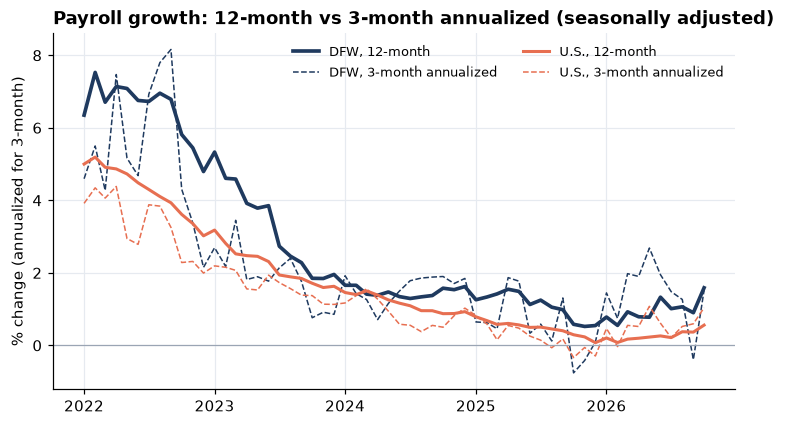

,DFW 12-mo growth %,U.S. 12-mo growth %,gap (pts),DFW avg monthly gain (K)
2017-2019,2.61,1.50,1.12,8.07
2023,3.27,2.20,1.07,6.76
2024,1.47,1.15,0.32,5.72
2025,1.09,0.47,0.62,1.96
latest 12 months,0.90,0.25,0.65,5.70


In **Oct 2026** (preliminary), DFW payrolls were 1.59% above a year earlier and grew at a 1.52% annualized rate over the latest three months; the U.S. figures were 0.56% and 1.04%. Over the latest 12 months DFW's 12-month growth averaged 0.90%, against 2.61% in 2017–2019, and average monthly gains were 5.7K vs 8.1K (2025 alone: 2.0K).

**Base effect.** The Oct 2026 12-month change compares with Oct 2025, when payrolls fell by 10.6K in DFW and 140K nationally. That dip flatters the latest 12-month comparison: one month earlier, DFW's 12-month growth was 0.90%.

In [2]:
cols = ["jobs_dfw_yoy_pct", "jobs_dfw_3m_ann_pct", "jobs_us_yoy_pct", "jobs_us_3m_ann_pct"]
x = d.loc["2022-01-01":, cols]
fig, ax = plt.subplots()
ax.plot(x.index, x["jobs_dfw_yoy_pct"], color=NAVY, lw=2.4, label="DFW, 12-month")
ax.plot(x.index, x["jobs_dfw_3m_ann_pct"], color=NAVY, lw=1, ls="--", label="DFW, 3-month annualized")
ax.plot(x.index, x["jobs_us_yoy_pct"], color=ORANGE, lw=2, label="U.S., 12-month")
ax.plot(x.index, x["jobs_us_3m_ann_pct"], color=ORANGE, lw=1, ls="--", label="U.S., 3-month annualized")
ax.axhline(0, color="#9aa5b4", lw=0.8)
ax.set_ylabel("% change (annualized for 3-month)")
ax.set_title("Payroll growth: 12-month vs 3-month annualized (seasonally adjusted)")
ax.legend(ncols=2, fontsize=8.5)
plt.show()

t, _ = tf.last_valid(d["jobs_dfw_yoy_pct"])
base = t - pd.DateOffset(months=12)
latest = d.loc[t, cols]
periods = {"2017-2019": ("2017-01-01", "2019-12-01"), "2023": ("2023-01-01", "2023-12-01"),
           "2024": ("2024-01-01", "2024-12-01"), "2025": ("2025-01-01", "2025-12-01"),
           "latest 12 months": ((t - pd.DateOffset(months=11)).strftime("%Y-%m-%d"), t.strftime("%Y-%m-%d"))}
table = pd.DataFrame({k: d.loc[a:b, ["jobs_dfw_yoy_pct", "jobs_us_yoy_pct", "jobs_gap_dfw_us_pp",
                                     "jobs_dfw_mom_k"]].mean() for k, (a, b) in periods.items()}).T
table.columns = ["DFW 12-mo growth %", "U.S. 12-mo growth %", "gap (pts)", "DFW avg monthly gain (K)"]
display(table.round(2))

display(Markdown(
    f"In **{m(t)}** (preliminary), DFW payrolls were {latest['jobs_dfw_yoy_pct']:.2f}% above a year earlier and "
    f"grew at a {latest['jobs_dfw_3m_ann_pct']:.2f}% annualized rate over the latest three months; the U.S. "
    f"figures were {latest['jobs_us_yoy_pct']:.2f}% and {latest['jobs_us_3m_ann_pct']:.2f}%. "
    f"Over the latest 12 months DFW's 12-month growth averaged {table.loc['latest 12 months'].iloc[0]:.2f}%, "
    f"against {table.loc['2017-2019'].iloc[0]:.2f}% in 2017–2019, and average monthly gains were "
    f"{table.loc['latest 12 months'].iloc[3]:.1f}K vs {table.loc['2017-2019'].iloc[3]:.1f}K "
    f"(2025 alone: {table.loc['2025'].iloc[3]:.1f}K).\n\n"
    f"**Base effect.** The {m(t)} 12-month change compares with {m(base)}, when payrolls fell by "
    f"{abs(d.loc[base, 'jobs_dfw_mom_k']):.1f}K in DFW and {abs(d.loc[base, 'jobs_us_mom_k']):.0f}K nationally. "
    f"That dip flatters the latest 12-month comparison: one month earlier, DFW's 12-month growth was "
    f"{d.loc[t - pd.DateOffset(months=1), 'jobs_dfw_yoy_pct']:.2f}%."))

## 2. Has DFW's edge over the U.S. shrunk?

The gap is DFW's 12-month job growth minus the U.S. rate. I compare the 2017–2019 average with the latest
12 months by regressing the gap on a constant and a "recent period" dummy. Monthly 12-month changes overlap
by 11 months, so ordinary standard errors would be far too small; the regression uses Newey–West (HAC)
standard errors with 12 lags. Caveats: 48 overlapping monthly observations carry roughly four years of
independent information, and HAC treats the jump from December 2019 to the recent window as adjacent
months. Read the test as indicative, not definitive.

In [3]:
def recent_vs_pre(col, lags=12):
    pre = d.loc["2017-01-01":"2019-12-01", col]
    rec = d.loc[periods["latest 12 months"][0]:periods["latest 12 months"][1], col]
    y = pd.concat([pre, rec])
    X = sm.add_constant(pd.Series([0] * len(pre) + [1] * len(rec), index=y.index, name="recent"))
    fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    lo, hi = fit.conf_int().loc["recent"]
    return {"2017-19 mean": fit.params["const"], "difference (recent - 2017-19)": fit.params["recent"],
            "HAC s.e.": fit.bse["recent"], "95% CI low": lo, "95% CI high": hi, "p-value": fit.pvalues["recent"],
            "n months": int(fit.nobs)}

tests = pd.DataFrame({"DFW minus U.S. gap (pts)": recent_vs_pre("jobs_gap_dfw_us_pp"),
                      "DFW 12-month growth (%)": recent_vs_pre("jobs_dfw_yoy_pct")}).T
shown = tests.astype({"n months": int}).round(3)
shown["p-value"] = tests["p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
display(shown)

g = tests.loc["DFW minus U.S. gap (pts)"]
gap_all = d.loc["2017-01-01":, "jobs_gap_dfw_us_pp"].dropna()
diff = g["difference (recent - 2017-19)"]
recent_gap = g["2017-19 mean"] + diff
if g["95% CI high"] < 0 and recent_gap > 0:
    verdict2 = "The edge has narrowed, and the interval excludes zero, but it has not closed"
elif g["95% CI low"] > 0:
    verdict2 = "The edge has widened, and the interval excludes zero"
else:
    verdict2 = "The interval includes zero, so the data cannot distinguish the two periods"
display(Markdown(
    f"DFW's edge over the U.S. averaged {g['2017-19 mean']:.2f} points in 2017–2019 and "
    f"{recent_gap:.2f} points in the latest 12 months, a difference of {diff:+.2f} points "
    f"(95% CI {g['95% CI low']:.2f} to {g['95% CI high']:.2f}). {verdict2}: DFW grew faster than the U.S. in "
    f"{(gap_all > 0).sum()} of the {len(gap_all)} months since January 2017."))

,2017-19 mean,difference (recent - 2017-19),HAC s.e.,95% CI low,95% CI high,p-value,n months
DFW minus U.S. gap (pts),1.12,-0.47,0.16,-0.78,-0.16,0.003,48
DFW 12-month growth (%),2.61,-1.72,0.16,-2.03,-1.40,<0.001,48


DFW's edge over the U.S. averaged 1.12 points in 2017–2019 and 0.65 points in the latest 12 months, a difference of -0.47 points (95% CI -0.78 to -0.16). The edge has narrowed, and the interval excludes zero, but it has not closed: DFW grew faster than the U.S. in 114 of the 118 months since January 2017.

## 3. Unemployment and a Sahm-rule-style gauge

BLS publishes the DFW unemployment rate only without seasonal adjustment. The dashboard estimates a
seasonally adjusted series (classical decomposition with fixed median monthly factors; see `src/transform.py`)
and validates the method by applying it to Texas and the U.S., where BLS's own seasonally adjusted series
exist. The **Sahm-rule-style gauge** is the 3-month average rate minus its lowest 3-month average in the prior
12 months. The 0.5-point threshold comes from the national rule; using it on a single metro is a heuristic.

,mean abs. error (pts),max abs. error (pts),share within 0.1 pt,months
tx,0.10,0.47,0.59,129.0
us,0.05,0.16,0.89,129.0


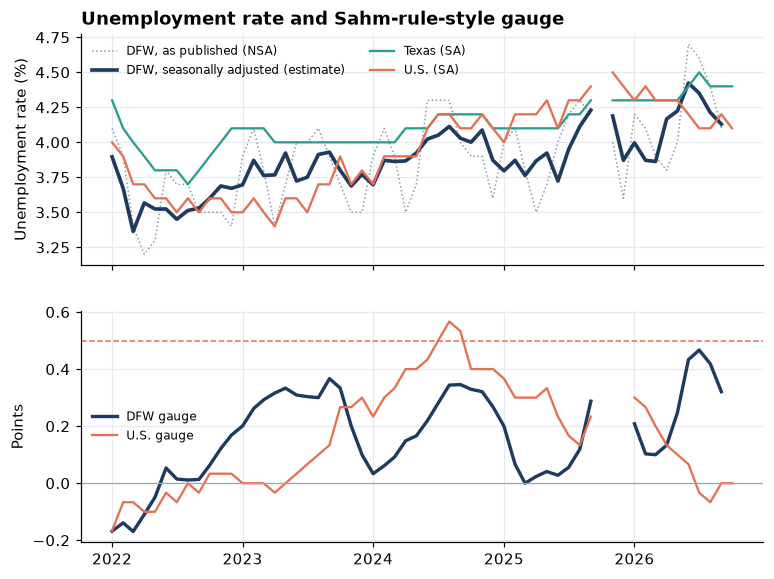

,latest,12-month high,month of high,months >= 0.5 since 2022,those months
median factors (dashboard),0.32,0.47,Jul 2026,0,none
mean factors,0.13,0.47,Jul 2026,2,"Feb 2023, Mar 2023"
Texas official factors,0.27,0.33,Aug 2026,0,none


DFW's published (not seasonally adjusted) rate was 4.1% in Sep 2026, 0.1 point below a year earlier. The validation errors above (0.10 and 0.05 points on average) are small next to the 0.5 threshold but not negligible. Across the three adjustments, the gauge's high over the latest 12 months ranges from 0.33 to 0.47: below 0.5 in every version. One variant (mean factors) crossed 0.5 in Feb 2023 and Mar 2023, while DFW payrolls were 4.6% above a year earlier — a reminder that this gauge is fragile at the metro level.

In [4]:
chk = {}
for geo in ("tx", "us"):
    err = (d[f"ur_{geo}_sa_est"] - d[f"ur_{geo}_sa"]).dropna()
    chk[geo] = {"mean abs. error (pts)": err.abs().mean(), "max abs. error (pts)": err.abs().max(),
                "share within 0.1 pt": (err.abs() <= 0.1 + 1e-9).mean(), "months": len(err)}
display(pd.DataFrame(chk).T.round(3))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
x = d.loc["2022-01-01":]
a1.plot(x.index, x["ur_dfw_nsa"], color=GRAY, lw=1, ls=":", label="DFW, as published (NSA)")
a1.plot(x.index, x["ur_dfw_sa_est"], color=NAVY, lw=2.4, label="DFW, seasonally adjusted (estimate)")
a1.plot(x.index, x["ur_tx_sa"], color=TEAL, lw=1.5, label="Texas (SA)")
a1.plot(x.index, x["ur_us_sa"], color=ORANGE, lw=1.5, label="U.S. (SA)")
a1.set_ylabel("Unemployment rate (%)"); a1.legend(ncols=2, fontsize=8)
a1.set_title("Unemployment rate and Sahm-rule-style gauge")
a2.plot(x.index, x["sahm_dfw"], color=NAVY, lw=2.2, label="DFW gauge")
a2.plot(x.index, x["sahm_us"], color=ORANGE, lw=1.5, label="U.S. gauge")
a2.axhline(0.5, color=ORANGE, ls="--", lw=1); a2.axhline(0, color="#9aa5b4", lw=0.8)
a2.set_ylabel("Points"); a2.legend(fontsize=8)
plt.show()

# Sensitivity: the gauge under three ways of seasonally adjusting the DFW rate
nsa = d["ur_dfw_nsa"]
def mean_factors(s):
    m12 = s.rolling(12).mean()
    dev = s - 0.5 * (m12.shift(-5) + m12.shift(-6))
    dev = dev[~((dev.index >= tf.PANDEMIC[0]) & (dev.index <= tf.PANDEMIC[1]))].dropna()
    f = dev.groupby(dev.index.month).mean()
    return s - s.index.month.map(f - f.mean()).to_numpy()
variants = {"median factors (dashboard)": tf.seasonal_adjust(nsa)[0],
            "mean factors": mean_factors(nsa),
            "Texas official factors": nsa - (d["ur_tx_nsa"] - d["ur_tx_sa"])}
ts, _ = tf.last_valid(d["sahm_dfw"])
window = slice(ts - pd.DateOffset(months=11), ts)
rows = {}
for name, sa in variants.items():
    gauge, _ = tf.sahm_gauge(sa)
    w = gauge.loc[window]
    hits = gauge.loc["2022-01-01":][gauge.loc["2022-01-01":] >= 0.5]
    rows[name] = {"latest": gauge.loc[ts], "12-month high": w.max(), "month of high": m(w.idxmax()),
                  "months >= 0.5 since 2022": len(hits),
                  "those months": ", ".join(m(i) for i in hits.index) or "none"}
sens = pd.DataFrame(rows).T
display(sens)

t_u, ur = tf.last_valid(d["ur_dfw_nsa"])
mean_hits = tf.sahm_gauge(variants["mean factors"])[0].loc["2022-01-01":]
mean_hits = mean_hits[mean_hits >= 0.5]
note = ""
if len(mean_hits):
    lo_g, hi_g = d.loc[mean_hits.index, "jobs_dfw_yoy_pct"].min(), d.loc[mean_hits.index, "jobs_dfw_yoy_pct"].max()
    growth = f"{lo_g:.1f}%" if round(lo_g, 1) == round(hi_g, 1) else f"{lo_g:.1f}%–{hi_g:.1f}%"
    note = (f" One variant (mean factors) crossed 0.5 in {' and '.join(m(i) for i in mean_hits.index)}, while DFW "
            f"payrolls were {growth} above a year earlier — a reminder that this gauge is fragile at the metro level.")
display(Markdown(
    f"DFW's published (not seasonally adjusted) rate was {ur:.1f}% in {m(t_u)}, "
    f"{abs(d.loc[t_u, 'ur_dfw_nsa_12m_change_pp']):.1f} point "
    f"{'below' if d.loc[t_u, 'ur_dfw_nsa_12m_change_pp'] < 0 else 'above'} a year earlier. The validation errors above "
    f"({chk['tx']['mean abs. error (pts)']:.2f} and {chk['us']['mean abs. error (pts)']:.2f} points on average) are "
    f"small next to the 0.5 threshold but not negligible. Across the three adjustments, the gauge's high over the "
    f"latest 12 months ranges from {sens['12-month high'].min():.2f} to {sens['12-month high'].max():.2f}"
    + (": below 0.5 in every version." if (sens['12-month high'] < 0.5).all() else
       ": at least one version reaches the 0.5 threshold.") + note))

## 4. Real wages

Average hourly earnings (all private-sector employees, not seasonally adjusted) compared with CPI-U
inflation over the same 12 months. Two deflators: the DFW CPI-U (published every other month, small sample)
and the U.S. CPI-U (monthly). Metro earnings are noisy and shift with the mix of jobs, so averages over
several months say more than any single month.

In [5]:
def _wage_words(a, b):
    if abs(a) < 1 and abs(b) < 1:
        return "With averages that close to zero, pay is roughly keeping pace with prices, no more."
    if a >= 1 and b >= 1:
        return "Pay is outpacing prices on either measure."
    if a <= -1 and b <= -1:
        return "Pay is falling behind prices on either measure."
    return "The answer depends on the price index used."

tc, _ = tf.last_valid(d["real_ahe_vs_dfw_cpi_pp"])
win = d.loc[tc - pd.DateOffset(months=11):tc]
summary = pd.DataFrame({
    "latest (CPI month)": [d.loc[tc, "ahe_dfw_yoy_pct"], d.loc[tc, "cpi_dfw_yoy_pct"], d.loc[tc, "cpi_us_yoy_pct"],
                           d.loc[tc, "real_ahe_vs_dfw_cpi_pp"], d.loc[tc, "real_ahe_vs_us_cpi_pp"]],
    "12-month average": [win["ahe_dfw_yoy_pct"].mean(), win["cpi_dfw_yoy_pct"].mean(), win["cpi_us_yoy_pct"].mean(),
                         win["real_ahe_vs_dfw_cpi_pp"].mean(), win["real_ahe_vs_us_cpi_pp"].mean()],
    "months with data": [win[c].notna().sum() for c in ["ahe_dfw_yoy_pct", "cpi_dfw_yoy_pct", "cpi_us_yoy_pct",
                                                         "real_ahe_vs_dfw_cpi_pp", "real_ahe_vs_us_cpi_pp"]],
}, index=["DFW hourly earnings growth (%)", "DFW CPI-U inflation (%)", "U.S. CPI-U inflation (%)",
          "real wage growth vs DFW CPI (pts)", "real wage growth vs U.S. CPI (pts)"])
display(summary.round(2))
sd = d.loc[tc - pd.DateOffset(months=35):tc, "real_ahe_vs_us_cpi_pp"].std()
display(Markdown(
    f"In {m(tc)}, real wage growth was {d.loc[tc, 'real_ahe_vs_dfw_cpi_pp']:+.2f} points against DFW prices and "
    f"{d.loc[tc, 'real_ahe_vs_us_cpi_pp']:+.2f} against U.S. prices; averaged over the 12 months to {m(tc)} it was "
    f"{summary.loc['real wage growth vs DFW CPI (pts)', '12-month average']:+.2f} and "
    f"{summary.loc['real wage growth vs U.S. CPI (pts)', '12-month average']:+.2f} points. The month-to-month "
    f"standard deviation of the U.S.-CPI version over the last three years is {sd:.2f} points. "
    + _wage_words(summary.loc['real wage growth vs DFW CPI (pts)', '12-month average'],
                  summary.loc['real wage growth vs U.S. CPI (pts)', '12-month average'])))

,latest (CPI month),12-month average,months with data
DFW hourly earnings growth (%),3.71,3.55,12
DFW CPI-U inflation (%),2.96,2.04,6
U.S. CPI-U inflation (%),3.74,3.23,11
real wage growth vs DFW CPI (pts),0.75,1.83,6
real wage growth vs U.S. CPI (pts),-0.03,0.24,11


In Sep 2026, real wage growth was +0.75 points against DFW prices and -0.03 against U.S. prices; averaged over the 12 months to Sep 2026 it was +1.83 and +0.24 points. The month-to-month standard deviation of the U.S.-CPI version over the last three years is 1.99 points. The answer depends on the price index used.

## 5. How broad is job growth?

Share of the 10 DFW supersectors with more jobs than a year earlier (not seasonally adjusted, so each is
compared with the same month a year earlier), and how concentrated the latest year's net gain is. The 10
supersectors add up exactly to total nonfarm jobs, which is checked below.

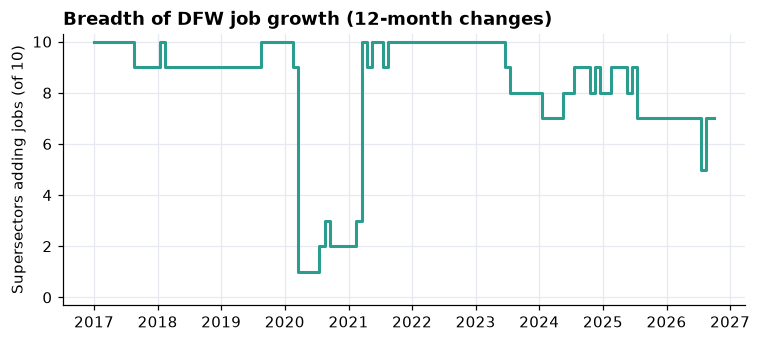

,supersector,jobs_k,yoy_k,yoy_pct,share_of_net_pct
0,Professional & business services,829.8,44.6,5.7,64.7
1,"Trade, transportation & utilities",908.4,13.7,1.5,19.9
2,"Mining, logging & construction",277.7,10.6,4.0,15.4
3,Manufacturing,315.2,2.8,0.9,4.1
4,Private education & health services,529.2,2.6,0.5,3.8
5,Financial activities,394.3,2.1,0.5,3.0
6,Leisure & hospitality,431.8,0.6,0.1,0.9
7,Other services,142.3,-0.3,-0.2,-0.4
8,Government,491.3,-3.7,-0.7,-5.4
9,Information,82.8,-4.1,-4.7,-6.0


Over the year to Oct 2026 (preliminary), 7 of 10 supersectors added jobs, but the gains were concentrated: professional & business services added 44.6K, 65% of the net 68.9K. Largest decline: information (-4.1K). Check: the sum of the 10 supersectors minus total nonfarm is 0.00K in every month.

In [6]:
br = d["breadth_share_pos"].dropna().loc["2017-01-01":]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(br.index, br / 10, color=TEAL, lw=2, drawstyle="steps-mid")
ax.set_ylim(-0.3, 10.3); ax.set_ylabel("Supersectors adding jobs (of 10)")
ax.set_title("Breadth of DFW job growth (12-month changes)")
plt.show()

last = ss["date"].max()
cur = ss[ss["date"] == last].sort_values("yoy_k", ascending=False)
net = cur["yoy_k"].sum()
cur = cur.assign(share_of_net_pct=cur["yoy_k"] / net * 100)
display(cur[["supersector", "jobs_k", "yoy_k", "yoy_pct", "share_of_net_pct"]].round(1).reset_index(drop=True))
top = cur.iloc[0]
display(Markdown(
    f"Over the year to {m(last)} (preliminary), {int((cur['yoy_k'] > 0).sum())} of 10 supersectors added jobs, "
    f"but the gains were concentrated: {top['supersector'].lower()} added {top['yoy_k']:.1f}K, "
    f"{top['share_of_net_pct']:.0f}% of the net {net:.1f}K. Largest decline: {cur.iloc[-1]['supersector'].lower()} "
    f"({cur.iloc[-1]['yoy_k']:+.1f}K). Check: the sum of the 10 supersectors minus total nonfarm is "
    f"{d['ss_sum_minus_total_k'].abs().max():.2f}K in every month."))

## 6. Verdict

A checklist of cooling signals, each computed from the data above. "Yes" means the signal points to
cooling.

In [7]:
t, _ = tf.last_valid(d["jobs_dfw_yoy_pct"])
avg12 = table.loc["latest 12 months"]
checks = [
    ("12-month job growth below its 2017-2019 average",
     avg12["DFW 12-mo growth %"] < table.loc["2017-2019", "DFW 12-mo growth %"],
     f"{avg12['DFW 12-mo growth %']:.2f}% vs {table.loc['2017-2019', 'DFW 12-mo growth %']:.2f}%"),
    ("Growth decelerating (3-month annualized more than 0.25 pt below 12-month)",
     d.loc[t, "jobs_dfw_3m_ann_pct"] < d.loc[t, "jobs_dfw_yoy_pct"] - 0.25,
     f"{d.loc[t, 'jobs_dfw_3m_ann_pct']:.2f}% vs {d.loc[t, 'jobs_dfw_yoy_pct']:.2f}% ({m(t)})"),
    ("DFW no longer outgrowing the U.S. (latest 12-month average gap <= 0)",
     avg12["gap (pts)"] <= 0, f"gap {avg12['gap (pts)']:+.2f} pts"),
    ("Unemployment rate higher than a year earlier (as published)",
     d.loc[t_u, "ur_dfw_nsa_12m_change_pp"] > 0, f"{d.loc[t_u, 'ur_dfw_nsa_12m_change_pp']:+.1f} pts ({m(t_u)})"),
    ("Sahm-style gauge at or above 0.5 in the latest 12 months (any adjustment method)",
     (sens["12-month high"] >= 0.5).any(), f"high {sens['12-month high'].max():.2f}"),
    ("Fewer than half of supersectors adding jobs",
     d["breadth_share_pos"].dropna().iloc[-1] < 50, f"{d['breadth_share_pos'].dropna().iloc[-1] / 10:.0f} of 10"),
    ("Real wages falling (12-month average below -0.5 pt vs U.S. CPI)",
     summary.loc["real wage growth vs U.S. CPI (pts)", "12-month average"] < -0.5,
     f"{summary.loc['real wage growth vs U.S. CPI (pts)', '12-month average']:+.2f} pts"),
]
verdict = pd.DataFrame(checks, columns=["signal", "cooling?", "evidence"])
verdict["cooling?"] = verdict["cooling?"].map({True: "yes", False: "no"})
display(verdict)
on = [c[0] for c in checks if c[1]]
off = [c[0] for c in checks if not c[1]]
if checks[0][1] and len(on) <= 2:
    overall = ("**Answer: cooled, not contracting.** Growth has slowed well below its pre-pandemic pace, but the "
               "broader signals do not show a downturn.")
elif not on:
    overall = "**Answer: no sign of cooling** on these measures."
else:
    overall = ("**Answer: cooling on several fronts at once.** Treat the market as weakening and watch the next "
               "releases.")
display(Markdown(
    f"{overall} {len(on)} of {len(checks)} cooling signals {'is' if len(on) == 1 else 'are'} on"
    + (f" ({'; '.join(on)})" if on else "")
    + (f". Not on: {'; '.join(off)}." if off else ".")
    + " The latest month is preliminary, and the annual benchmark revision can move these figures."))

,signal,cooling?,evidence
0,12-month job growth below its 2017-2019 average,yes,0.90% vs 2.61%
1,Growth decelerating (3-month annualized more t...,no,1.52% vs 1.59% (Oct 2026)
2,DFW no longer outgrowing the U.S. (latest 12-m...,no,gap +0.65 pts
3,Unemployment rate higher than a year earlier (...,no,-0.1 pts (Sep 2026)
4,Sahm-style gauge at or above 0.5 in the latest...,no,high 0.47
5,Fewer than half of supersectors adding jobs,no,7 of 10
6,Real wages falling (12-month average below -0....,no,+0.24 pts


**Answer: cooled, not contracting.** Growth has slowed well below its pre-pandemic pace, but the broader signals do not show a downturn. 1 of 7 cooling signals is on (12-month job growth below its 2017-2019 average). Not on: Growth decelerating (3-month annualized more than 0.25 pt below 12-month); DFW no longer outgrowing the U.S. (latest 12-month average gap <= 0); Unemployment rate higher than a year earlier (as published); Sahm-style gauge at or above 0.5 in the latest 12 months (any adjustment method); Fewer than half of supersectors adding jobs; Real wages falling (12-month average below -0.5 pt vs U.S. CPI). The latest month is preliminary, and the annual benchmark revision can move these figures.

### Caveats

* **Preliminary and revised data.** The latest month of state and metro data is preliminary, and BLS
  re-benchmarks state and metro payrolls and unemployment rates each year (released with January data in
  March), which can revise the history used here.
* **Seasonal adjustment.** The DFW unemployment rate is adjusted by this project, not by BLS; the gauge
  built on it moves with the method, as shown in section 3.
* **Definitions differ.** Unemployment (LAUS) counts residents; payroll jobs (CES) count jobs located in the
  metro, including commuters and second jobs, and exclude the self-employed.
* **Observational data.** These are descriptive comparisons, not causal estimates; the HAC test in section 2
  addresses autocorrelation but not changes in the composition of the economy.
* **Missing month.** BLS did not publish October 2025 values for unemployment rates or the U.S. CPI
  ("Data unavailable due to the 2025 lapse in appropriations"); calculations that need that month are left blank.